# Salifort Motors | Modeling and evaluation
**Sebastián Madrigal López · Google Advanced Data Analytics capstone project**

This notebook covers **Construct** and **Execute** in the PACE framework. It compares
decision trees and random forests under two feature scenarios, selects a model using
cross-validation, and evaluates its performance and predictive inputs.

Run the notebook from top to bottom. Data preparation is included for independent
execution. See [Data exploration](01_data_exploration.ipynb) for the descriptive findings.


## 1. Setup


In [1]:
from pathlib import Path
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, accuracy_score,
    confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay,
)


In [2]:
# A notebook can start from the repository folder or its notebooks subfolder.
project_folder = Path.cwd()
if project_folder.name == 'notebooks':
    project_folder = project_folder.parent

data_file = project_folder / 'data' / 'raw' / 'HR_capstone_dataset.csv'
reports_folder = project_folder / 'reports'
figures_folder = reports_folder / 'figures'
tables_folder = reports_folder / 'tables'

if not data_file.is_file():
    raise FileNotFoundError('Open this notebook from the repository or notebooks folder.')

figures_folder.mkdir(parents=True, exist_ok=True)
tables_folder.mkdir(parents=True, exist_ok=True)


In [3]:
# Shared colors keep the figures consistent across both notebooks.
teal = '#167D8D'
coral = '#DB765F'
ink = '#16324A'
muted = '#627487'

plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 170,
    'font.family': 'DejaVu Sans',
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.labelcolor': ink,
    'text.color': ink,
    'xtick.color': muted,
    'ytick.color': muted,
    'axes.titleweight': 'bold',
    'axes.titlepad': 15,
})
pd.set_option('display.max_columns', 20)


## 2. Data preparation
Remove exact repeated rows, standardize column names and retain source row indices.
Deduplication assumes identical records are redundant observations.


In [4]:
df = pd.read_csv(data_file)

print('Rows and columns:', df.shape)
print('Missing values:', df.isna().sum().sum())
print('Exact repeated rows:', df.duplicated().sum())


Rows and columns: (14999, 10)
Missing values: 0
Exact repeated rows: 3008


In [5]:
expected_columns = [
    'satisfaction_level', 'last_evaluation', 'number_project',
    'average_montly_hours', 'time_spend_company', 'Work_accident',
    'left', 'promotion_last_5years', 'Department', 'salary',
]

if set(df.columns) != set(expected_columns):
    raise ValueError('Unexpected columns. Review the CSV and data/README.md.')
if df.isna().any().any():
    raise ValueError('Missing values found. Review them before continuing.')
if not df['left'].isin([0, 1]).all():
    raise ValueError('The target must contain only 0 (stayed) and 1 (left).')


In [6]:
# Keep the source data in df and the analysis data in df1.
df1 = df.drop_duplicates().copy()

df1 = df1.rename(columns={
    'average_montly_hours': 'average_monthly_hours',
    'time_spend_company': 'tenure',
    'Work_accident': 'work_accident',
    'Department': 'department',
})

# Preserve source row indices for split traceability.
print('Rows before cleaning:', len(df))
print('Exact repeats removed:', len(df) - len(df1))
print('Rows after cleaning:', len(df1))
display(df1.head())


Rows before cleaning: 14999
Exact repeats removed: 3008
Rows after cleaning: 11991


,satisfaction_level,last_evaluation,number_project,average_monthly_hours,tenure,work_accident,left,promotion_last_5years,department,salary
0,0.38,0.53,2,157,3,0,1,0,sales,low
1,0.80,0.86,5,262,6,0,1,0,sales,medium
2,0.11,0.88,7,272,4,0,1,0,sales,medium
3,0.72,0.87,5,223,5,0,1,0,sales,low
4,0.37,0.52,2,159,3,0,1,0,sales,low


## 3. Predictors, target and test partition
`X` contains the predictors and `y` contains `left` (**1 = left, 0 = stayed**).
Reserve 25% of rows for testing with stratification and `random_state=0`.
Training data support feature-scenario comparison and hyperparameter selection.


In [7]:
y = df1['left']
X = df1.drop(columns='left')

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=0,
)

print('Training rows:', len(X_train))
print('Test rows:', len(X_test))
print('Training departure rate:', round(y_train.mean(), 4))
print('Test departure rate:', round(y_test.mean(), 4))


Training rows: 8993
Test rows: 2998
Training departure rate: 0.166
Test departure rate: 0.1661


## 4. Categorical encoding
A column transformer applies the following encoding within each CV training fold.

| Column | Transformation |
|---|---|
| `salary` | Ordered encoding: low = 0, medium = 1, high = 2 |
| `department` | One indicator column per department |
| Other columns | Retained as supplied |

Unseen salary categories receive -1; unseen departments receive zeros across their indicators.


In [8]:
salary_encoder = OrdinalEncoder(
    categories=[['low', 'medium', 'high']],
    handle_unknown='use_encoded_value',
    unknown_value=-1,
)

department_encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False,
)

preprocessor = ColumnTransformer(
    transformers=[
        ('salary', salary_encoder, ['salary']),
        ('department', department_encoder, ['department']),
    ],
    remainder='passthrough',
)


## 5. Comparison design
- **Full inputs:** all nine predictors.
- **Reduced inputs (primary scenario):** remove `satisfaction_level` and replace
  `average_monthly_hours` with `overworked = hours > 175`.

The reduced scenario assesses reliance on satisfaction and exact hours. The 175-hour
threshold is a fixed analytical assumption.

Four-fold shuffled stratified cross-validation (`random_state=0`) selects hyperparameters
by mean ROC AUC. The primary model is selected among the reduced-input candidates before
test evaluation. Classification uses the default 0.5 decision threshold.


In [9]:
cv = StratifiedKFold(
    n_splits=4,
    shuffle=True,
    random_state=0,
)

scoring = {
    'roc_auc': 'roc_auc',
    'average_precision': 'average_precision',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'accuracy': 'accuracy',
}


Each scenario evaluates **12 tree configurations** and **8 forest configurations**,
with 200 trees per forest. The result table reports all metrics for the configuration
selected by mean CV ROC AUC. `cv_roc_auc_sd` describes variation across the four folds.


In [10]:
def make_results(model_name, search, scenario, elapsed_seconds):
    # Select the configuration with the highest mean CV ROC AUC.
    search_results = pd.DataFrame(search.cv_results_)
    best_row = search_results.iloc[search.best_index_]

    # Report all metrics for the selected configuration.
    results = pd.DataFrame({
        'scenario': [scenario],
        'model': [model_name],
        'cv_roc_auc': [best_row['mean_test_roc_auc']],
        'cv_roc_auc_sd': [best_row['std_test_roc_auc']],
        'candidate_count': [len(search_results)],
        'fit_seconds': [elapsed_seconds],
        'best_params': [json.dumps(search.best_params_, sort_keys=True)],
        'cv_average_precision': [best_row['mean_test_average_precision']],
        'cv_precision': [best_row['mean_test_precision']],
        'cv_recall': [best_row['mean_test_recall']],
        'cv_f1': [best_row['mean_test_f1']],
        'cv_accuracy': [best_row['mean_test_accuracy']],
    })
    return results


## 6. Decision tree: full inputs


In [11]:
tree = DecisionTreeClassifier(random_state=0)


The pipeline combines categorical encoding and classification. Each CV round fits both
steps on its training rows and applies the fitted pipeline to its validation rows.


In [12]:
tree_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', tree),
])


The grid controls tree depth and the minimum observations per leaf and split.
The `model__` prefix targets the classifier step of the pipeline.


In [13]:
tree_params = {
    'model__max_depth': [4, 6, None],
    'model__min_samples_leaf': [2, 5],
    'model__min_samples_split': [2, 6],
}


`refit='roc_auc'` selects the configuration with the highest mean CV ROC AUC and fits it
on all training rows. The search uses two parallel workers.


In [14]:
tree1 = GridSearchCV(
    estimator=tree_pipeline,
    param_grid=tree_params,
    scoring=scoring,
    cv=cv,
    refit='roc_auc',
    n_jobs=2,
    error_score='raise',
    return_train_score=False,
)


In [15]:
start = time.perf_counter()
tree1.fit(X_train, y_train)
tree1_seconds = time.perf_counter() - start

print('Best tree parameters:', tree1.best_params_)
print('Mean CV ROC AUC:', round(tree1.best_score_, 4))
print('Training time (seconds):', round(tree1_seconds, 1))


Best tree parameters: {'model__max_depth': 6, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}
Mean CV ROC AUC: 0.9744
Training time (seconds): 2.2


In [16]:
tree1_results = make_results('Decision tree', tree1, 'full', tree1_seconds)
display(tree1_results.drop(columns='best_params').round(4))


,scenario,model,cv_roc_auc,cv_roc_auc_sd,candidate_count,fit_seconds,cv_average_precision,cv_precision,cv_recall,cv_f1,cv_accuracy
0,full,Decision tree,0.9744,0.0041,12,2.2406,0.9457,0.9694,0.9109,0.9392,0.9804


## 7. Random forest: full inputs


In [17]:
rf = RandomForestClassifier(random_state=0, n_jobs=1)

rf_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', rf),
])


Each forest contains 200 trees. The grid varies tree depth, leaf size and the number of
features considered per split. Each tree uses a bootstrap sample sized at 70% of the
available training rows. Parallelism is managed by the grid search.


In [18]:
rf_params = {
    'model__n_estimators': [200],
    'model__max_depth': [5, None],
    'model__max_features': [1.0, 'sqrt'],
    'model__max_samples': [0.7],
    'model__min_samples_leaf': [1, 3],
}

rf1 = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=rf_params,
    scoring=scoring,
    cv=cv,
    refit='roc_auc',
    n_jobs=2,
    error_score='raise',
    return_train_score=False,
)


In [19]:
start = time.perf_counter()
rf1.fit(X_train, y_train)
rf1_seconds = time.perf_counter() - start

print('Best forest parameters:', rf1.best_params_)
print('Mean CV ROC AUC:', round(rf1.best_score_, 4))
print('Training time (seconds):', round(rf1_seconds, 1))


Best forest parameters: {'model__max_depth': 5, 'model__max_features': 1.0, 'model__max_samples': 0.7, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Mean CV ROC AUC: 0.9818
Training time (seconds): 21.0


In [20]:
rf1_results = make_results('Random forest', rf1, 'full', rf1_seconds)
full_cv = pd.concat([tree1_results, rf1_results], ignore_index=True)
display(full_cv.drop(columns='best_params').round(4))


,scenario,model,cv_roc_auc,cv_roc_auc_sd,candidate_count,fit_seconds,cv_average_precision,cv_precision,cv_recall,cv_f1,cv_accuracy
0,full,Decision tree,0.9744,0.0041,12,2.2406,0.9457,0.9694,0.9109,0.9392,0.9804
1,full,Random forest,0.9818,0.0018,8,21.0114,0.9619,0.9490,0.9183,0.9333,0.9782


## 8. Reduced inputs
Remove satisfaction and replace exact monthly hours with the binary workload indicator.
Both feature scenarios use the same training and test rows.


In [21]:
X_train_reduced = X_train.drop(columns='satisfaction_level').copy()
X_test_reduced = X_test.drop(columns='satisfaction_level').copy()

X_train_reduced['overworked'] = (
    X_train_reduced['average_monthly_hours'] > 175
).astype(int)
X_test_reduced['overworked'] = (
    X_test_reduced['average_monthly_hours'] > 175
).astype(int)

X_train_reduced = X_train_reduced.drop(columns='average_monthly_hours')
X_test_reduced = X_test_reduced.drop(columns='average_monthly_hours')

print('Reduced predictor columns:', list(X_train_reduced.columns))
display(X_train_reduced.head())


Reduced predictor columns: ['last_evaluation', 'number_project', 'tenure', 'work_accident', 'promotion_last_5years', 'department', 'salary', 'overworked']


,last_evaluation,number_project,tenure,work_accident,promotion_last_5years,department,salary,overworked
9187,0.55,4,3,0,0,accounting,medium,1
7204,0.97,3,2,0,0,accounting,low,1
10499,0.73,4,5,0,0,technical,low,1
6424,0.89,3,4,1,0,sales,medium,1
3197,0.77,5,3,0,0,product_mng,high,1


## 9. Decision tree: reduced inputs
Apply the tree grid and CV strategy to the reduced predictors.


In [22]:
reduced_tree = DecisionTreeClassifier(random_state=0)

reduced_tree_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', reduced_tree),
])

tree2 = GridSearchCV(
    estimator=reduced_tree_pipeline,
    param_grid=tree_params,
    scoring=scoring,
    cv=cv,
    refit='roc_auc',
    n_jobs=2,
    error_score='raise',
    return_train_score=False,
)


In [23]:
start = time.perf_counter()
tree2.fit(X_train_reduced, y_train)
tree2_seconds = time.perf_counter() - start

print('Best reduced-tree parameters:', tree2.best_params_)
print('Mean CV ROC AUC:', round(tree2.best_score_, 4))
print('Training time (seconds):', round(tree2_seconds, 1))


Best reduced-tree parameters: {'model__max_depth': 6, 'model__min_samples_leaf': 2, 'model__min_samples_split': 6}
Mean CV ROC AUC: 0.9593
Training time (seconds): 0.7


In [24]:
tree2_results = make_results('Decision tree', tree2, 'reduced', tree2_seconds)
display(tree2_results.drop(columns='best_params').round(4))


,scenario,model,cv_roc_auc,cv_roc_auc_sd,candidate_count,fit_seconds,cv_average_precision,cv_precision,cv_recall,cv_f1,cv_accuracy
0,reduced,Decision tree,0.9593,0.0056,12,0.7149,0.8717,0.8401,0.8995,0.8679,0.9543


## 10. Random forest: reduced inputs
Apply the forest grid and CV strategy to the reduced predictors.


In [25]:
reduced_rf = RandomForestClassifier(random_state=0, n_jobs=1)

reduced_rf_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', reduced_rf),
])

rf2 = GridSearchCV(
    estimator=reduced_rf_pipeline,
    param_grid=rf_params,
    scoring=scoring,
    cv=cv,
    refit='roc_auc',
    n_jobs=2,
    error_score='raise',
    return_train_score=False,
)


In [26]:
start = time.perf_counter()
rf2.fit(X_train_reduced, y_train)
rf2_seconds = time.perf_counter() - start

print('Best reduced-forest parameters:', rf2.best_params_)
print('Mean CV ROC AUC:', round(rf2.best_score_, 4))
print('Training time (seconds):', round(rf2_seconds, 1))


Best reduced-forest parameters: {'model__max_depth': None, 'model__max_features': 'sqrt', 'model__max_samples': 0.7, 'model__min_samples_leaf': 3, 'model__n_estimators': 200}
Mean CV ROC AUC: 0.9672
Training time (seconds): 15.7


In [27]:
rf2_results = make_results('Random forest', rf2, 'reduced', rf2_seconds)
reduced_cv = pd.concat([tree2_results, rf2_results], ignore_index=True)
display(reduced_cv.drop(columns='best_params').round(4))


,scenario,model,cv_roc_auc,cv_roc_auc_sd,candidate_count,fit_seconds,cv_average_precision,cv_precision,cv_recall,cv_f1,cv_accuracy
0,reduced,Decision tree,0.9593,0.0056,12,0.7149,0.8717,0.8401,0.8995,0.8679,0.9543
1,reduced,Random forest,0.9672,0.0077,8,15.7260,0.9152,0.9188,0.8687,0.8926,0.9653


## 11. Model selection
Select the reduced-input candidate with the highest mean CV ROC AUC. Full-input models
provide a comparison of performance across the two feature scenarios.


In [28]:
cv_results = pd.concat([full_cv, reduced_cv], ignore_index=True)
comparison_columns = [
    'scenario', 'model', 'cv_roc_auc', 'cv_roc_auc_sd', 'cv_average_precision'
]
display(cv_results[comparison_columns].round(4))

if tree2.best_score_ >= rf2.best_score_:
    selected_name = 'Decision tree'
    selected_search = tree2
else:
    selected_name = 'Random forest'
    selected_search = rf2

# best_estimator_ contains the fitted preprocessor and classifier together.
selected_model = selected_search.best_estimator_
print('Selected reduced-input model:', selected_name)
print('Selection criterion: mean training CV ROC AUC')


Selected reduced-input model: Random forest
Selection criterion: mean training CV ROC AUC


,scenario,model,cv_roc_auc,cv_roc_auc_sd,cv_average_precision
0,full,Decision tree,0.9744,0.0041,0.9457
1,full,Random forest,0.9818,0.0018,0.9619
2,reduced,Decision tree,0.9593,0.0056,0.8717
3,reduced,Random forest,0.9672,0.0077,0.9152


## 12. Test-set evaluation
ROC AUC and average precision use predicted departure probabilities. Precision, recall,
F1 and accuracy use class predictions. Average precision summarizes the precision-recall
curve. All metrics treat `left=1` as the positive class.


In [29]:
def get_scores(model_name, model, X_test_data, y_test_data, scenario):
    probabilities = model.predict_proba(X_test_data)[:, 1]
    predictions = model.predict(X_test_data)

    auc = roc_auc_score(y_test_data, probabilities)
    average_precision = average_precision_score(y_test_data, probabilities)
    precision = precision_score(y_test_data, predictions, zero_division=0)
    recall = recall_score(y_test_data, predictions, zero_division=0)
    f1 = f1_score(y_test_data, predictions, zero_division=0)
    accuracy = accuracy_score(y_test_data, predictions)

    results = pd.DataFrame({
        'scenario': [scenario],
        'model': [model_name],
        'roc_auc': [auc],
        'average_precision': [average_precision],
        'precision': [precision],
        'recall': [recall],
        'f1': [f1],
        'accuracy': [accuracy],
    })
    return results


The baseline predicts the majority class and assigns the training departure rate as a
constant probability. Precision, recall and F1 are recorded as zero when it predicts
zero departures.


In [30]:
baseline = DummyClassifier(strategy='prior')
baseline.fit(X_train_reduced, y_train)

baseline_results = get_scores(
    'Majority baseline', baseline, X_test_reduced, y_test, 'baseline'
)
display(baseline_results.round(4))


,scenario,model,roc_auc,average_precision,precision,recall,f1,accuracy
0,baseline,Majority baseline,0.5,0.1661,0.0,0.0,0.0,0.8339


Evaluate the full-input models on the test partition.


In [31]:
tree1_test = get_scores(
    'Decision tree', tree1.best_estimator_, X_test, y_test, 'full'
)
rf1_test = get_scores(
    'Random forest', rf1.best_estimator_, X_test, y_test, 'full'
)


Evaluate the reduced-input models on the same test rows.


In [32]:
tree2_test = get_scores(
    'Decision tree', tree2.best_estimator_, X_test_reduced, y_test, 'reduced'
)
rf2_test = get_scores(
    'Random forest', rf2.best_estimator_, X_test_reduced, y_test, 'reduced'
)

test_results = pd.concat(
    [baseline_results, tree1_test, rf1_test, tree2_test, rf2_test],
    ignore_index=True,
)
display(test_results.round(4))


,scenario,model,roc_auc,average_precision,precision,recall,f1,accuracy
0,baseline,Majority baseline,0.5000,0.1661,0.0000,0.0000,0.0000,0.8339
1,full,Decision tree,0.9699,0.9420,0.9720,0.9056,0.9376,0.9800
2,full,Random forest,0.9842,0.9617,0.9622,0.9197,0.9405,0.9807
3,reduced,Decision tree,0.9516,0.8533,0.7839,0.9177,0.8455,0.9443
4,reduced,Random forest,0.9682,0.9045,0.9050,0.8795,0.8921,0.9646


The majority baseline achieves **83.4% accuracy** while detecting zero departures.
The selected reduced-input forest achieves **ROC AUC 0.968**, **precision 90.5%** and
**recall 88.0%**. The full-input forest reaches **ROC AUC 0.984**, indicating additional
predictive information in satisfaction and exact hours.


## 13. Classification errors
A false negative is a missed departure; a false positive is an employee who stayed
but was classified as leaving. The selected model detects **438 of 498 departures**,
with **60 false negatives** and **46 false positives**.


In [33]:
selected_probabilities = selected_model.predict_proba(X_test_reduced)[:, 1]
selected_predictions = selected_model.predict(X_test_reduced)

selected_test_results = get_scores(
    selected_name, selected_model, X_test_reduced, y_test, 'reduced'
)
selected_scores = selected_test_results.iloc[0].to_dict()
display(selected_test_results.round(4))


,scenario,model,roc_auc,average_precision,precision,recall,f1,accuracy
0,reduced,Random forest,0.9682,0.9045,0.905,0.8795,0.8921,0.9646


True negatives (stayed, predicted stayed): 2454
False positives (stayed, predicted left): 46
False negatives (left, predicted stayed): 60
True positives (left, predicted left): 438


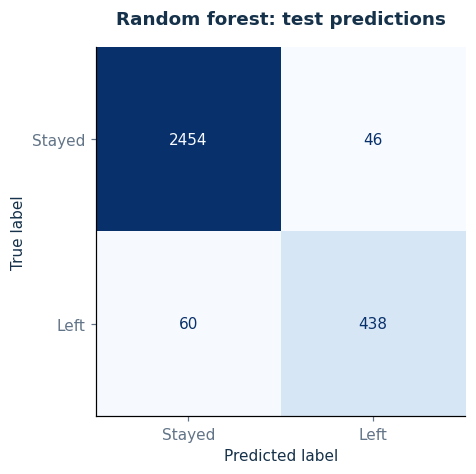

In [34]:
cm = confusion_matrix(y_test, selected_predictions, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print('True negatives (stayed, predicted stayed):', tn)
print('False positives (stayed, predicted left):', fp)
print('False negatives (left, predicted stayed):', fn)
print('True positives (left, predicted left):', tp)

fig, ax = plt.subplots(figsize=(5.3, 4.2), layout='constrained')
ConfusionMatrixDisplay(cm, display_labels=['Stayed', 'Left']).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d'
)
ax.set_title(f'{selected_name}: test predictions')
fig.savefig(figures_folder / 'confusion_matrix.png', bbox_inches='tight')
plt.show()


The precision-recall curve shows the threshold tradeoff. The highlighted point represents
the default 0.5 decision rule used for the reported classification metrics.


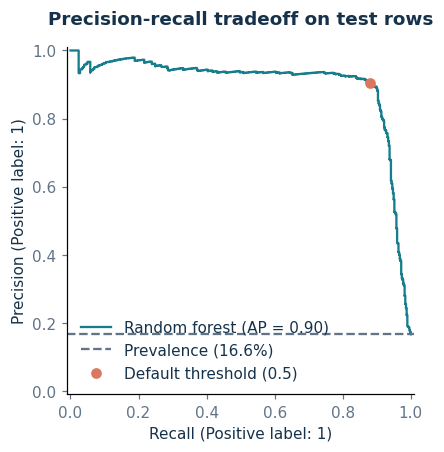

In [35]:
fig, ax = plt.subplots(figsize=(6.7, 4), layout='constrained')
PrecisionRecallDisplay.from_predictions(
    y_test, selected_probabilities, ax=ax, name=selected_name, color=teal
)
ax.axhline(y_test.mean(), color=muted, linestyle='--',
           label=f'Prevalence ({y_test.mean():.1%})')
ax.scatter(selected_scores['recall'], selected_scores['precision'],
           color=coral, zorder=4, label='Default threshold (0.5)')
ax.set_title('Precision-recall tradeoff on test rows')
ax.legend(frameon=False, loc='lower left')
fig.savefig(figures_folder / 'precision_recall.png', bbox_inches='tight')
plt.show()


## 14. Model interpretation
Permutation importance measures the decrease in ROC AUC after shuffling an input column.
It is computed on test rows after selection, using five repeats and `random_state=0`.
Error bars show standard deviations across repeats. Correlated features can share
predictive information, affecting their individual importance estimates.


In [36]:
permutation = permutation_importance(
    selected_model,
    X_test_reduced,
    y_test,
    scoring='roc_auc',
    n_repeats=5,
    random_state=0,
    n_jobs=2,
)

importance = pd.DataFrame({
    'feature': X_test_reduced.columns,
    'importance_mean': permutation.importances_mean,
    'importance_sd': permutation.importances_std,
})
importance = importance.sort_values('importance_mean', ascending=False)
display(importance.round(4))


,feature,importance_mean,importance_sd
1,number_project,0.1965,0.0108
2,tenure,0.1005,0.0044
0,last_evaluation,0.0870,0.0035
7,overworked,0.0248,0.0021
6,salary,0.0011,0.0010
3,work_accident,0.0005,0.0008
4,promotion_last_5years,0.0001,0.0000
5,department,-0.0012,0.0006


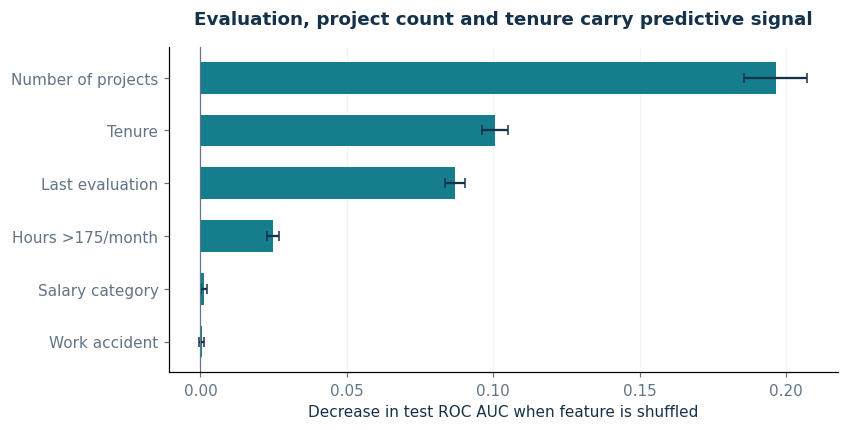

In [37]:
feature_labels = {
    'last_evaluation': 'Last evaluation',
    'number_project': 'Number of projects',
    'tenure': 'Tenure',
    'overworked': 'Hours >175/month',
    'salary': 'Salary category',
    'department': 'Department',
    'work_accident': 'Work accident',
    'promotion_last_5years': 'Promotion in last 5 years',
}
top_features = importance.head(6).sort_values('importance_mean')
labels = top_features['feature'].map(feature_labels)

fig, ax = plt.subplots(figsize=(7.6, 3.8), layout='constrained')
ax.barh(labels, top_features['importance_mean'],
        xerr=top_features['importance_sd'], color=teal, height=0.6,
        error_kw={'ecolor': ink, 'capsize': 3})
ax.axvline(0, color=muted, linewidth=0.8)
ax.set_title('Evaluation, project count and tenure carry predictive signal')
ax.set_xlabel('Decrease in test ROC AUC when feature is shuffled')
ax.grid(axis='x', alpha=0.13)
ax.set_axisbelow(True)
fig.savefig(figures_folder / 'feature_importance.png', bbox_inches='tight')
plt.show()


## 15. Recommendations and limitations
Project count, tenure and evaluation scores provide priorities for follow-up with HR.
Review project allocation at both workload extremes, career progression and how
evaluations relate to workload. A support intervention should include a defined outcome
and a prospective evaluation plan.

Findings describe predictive associations in the supplied educational dataset. Collection
dates, exit type, employee identifiers and predictor timing remain undocumented.
Deduplication and the 175-hour cutoff are analytical assumptions. Generalization requires
validation on a later cohort, with predictor availability verified at the intended
prediction time. Probability calibration and intervention costs require further assessment.


## Appendix: exported outputs
Save model comparisons, complete search results, split membership, data audit and
package versions for reproducibility.


In [38]:
cv_results.to_csv(tables_folder / 'cross_validation_results.csv', index=False)
test_results.to_csv(tables_folder / 'test_results.csv', index=False)
importance.to_csv(tables_folder / 'permutation_importance.csv', index=False)

pd.DataFrame(tree1.cv_results_).to_csv(
    tables_folder / 'grid_full_decision_tree.csv', index=False
)
pd.DataFrame(rf1.cv_results_).to_csv(
    tables_folder / 'grid_full_random_forest.csv', index=False
)
pd.DataFrame(tree2.cv_results_).to_csv(
    tables_folder / 'grid_reduced_decision_tree.csv', index=False
)
pd.DataFrame(rf2.cv_results_).to_csv(
    tables_folder / 'grid_reduced_random_forest.csv', index=False
)


In [39]:
train_membership = pd.DataFrame({
    'source_row': X_train.index,
    'partition': 'train',
})
test_membership = pd.DataFrame({
    'source_row': X_test.index,
    'partition': 'test',
})
split_membership = pd.concat([train_membership, test_membership], ignore_index=True)
split_membership = split_membership.sort_values('source_row')
split_membership.to_csv(tables_folder / 'split_membership.csv', index=False)


In [40]:
import hashlib
import platform
import importlib.metadata


In [41]:
# This fingerprint identifies the exact source file used in the analysis.
source_hash = hashlib.sha256(data_file.read_bytes()).hexdigest()

audit = {
    'raw_rows': len(df),
    'columns': df.shape[1],
    'duplicate_rows_removed': len(df) - len(df1),
    'analysis_rows': len(df1),
    'missing_values': int(df.isna().sum().sum()),
    'raw_departures': int(df['left'].sum()),
    'analysis_departures': int(df1['left'].sum()),
    'analysis_departure_rate': float(df1['left'].mean()),
    'source_sha256': source_hash,
}


In [42]:
environment = {'python': platform.python_version()}
packages = [
    'numpy', 'pandas', 'scipy', 'scikit-learn', 'matplotlib', 'seaborn',
    'joblib', 'threadpoolctl', 'reportlab', 'Pillow',
]
for package in packages:
    environment[package] = importlib.metadata.version(package)

summary = {
    'audit': audit,
    'train_rows': len(X_train),
    'test_rows': len(X_test),
    'test_departures': int(y_test.sum()),
    'seed': 0,
    'threshold': 0.5,
    'selected_model': selected_name,
    'selected_scenario': 'reduced',
    'selection_metric': 'training four-fold CV ROC AUC',
    'selected_cv_roc_auc': float(selected_search.best_score_),
    'selected_best_params': selected_search.best_params_,
    'selected_test_scores': selected_scores,
    'confusion_matrix': cm.tolist(),
    'top_features': importance.head(4)['feature'].tolist(),
    'environment': environment,
}

metrics_text = json.dumps(summary, indent=2) + '\n'
(reports_folder / 'metrics.json').write_text(metrics_text)
print('Saved metrics, grid-search results and split membership.')


Saved metrics, grid-search results and split membership.
